In [2]:
import fitz
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.patches import PathPatch
import numpy as np


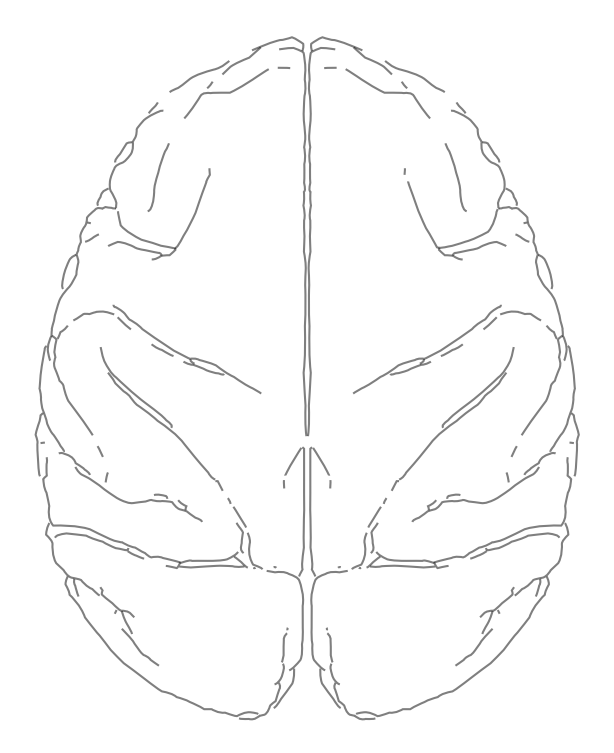

In [3]:
def plot_cortical_frame(fname=None, ax=None):
    if ax is None:
        ax = plt.gca()
    
    if fname is None:
        fname = "viz/cortex.pdf"

    pdf = fitz.open(fname)
    page = pdf[0]
    H = page.rect.height
    W = page.rect.width

    for drawing in page.get_drawings():

        verts = []
        codes = []

        for item in drawing["items"]:

            if item[0] == "c":  # cubic Bezier

                p1, p2, p3, p4 = item[1:]

                if len(verts) == 0:
                    verts.append((p1.x, H-p1.y))
                    codes.append(Path.MOVETO)

                verts.extend([
                    (p1.x, H-p1.y),
                    (p2.x, H-p2.y),
                    (p3.x, H-p3.y),
                    # (p4.x, H-p4.y),
                ])

                codes.extend([
                    Path.CURVE4,
                    Path.CURVE4,
                    Path.CURVE4,
                    # Path.CURVE4,
                ])

        if len(verts):

            path = Path(verts, codes)

            patch = PathPatch(
                path,
                facecolor='none',
                edgecolor='k',
                alpha=.5,
                lw=.5
            )

            ax.add_patch(patch)

    ax.set_xlim(0, W)
    ax.set_ylim(0, H)
    ax.set_aspect("equal")
    ax.axis("off")

# fig, ax = plt.subplots()
plot_cortical_frame()

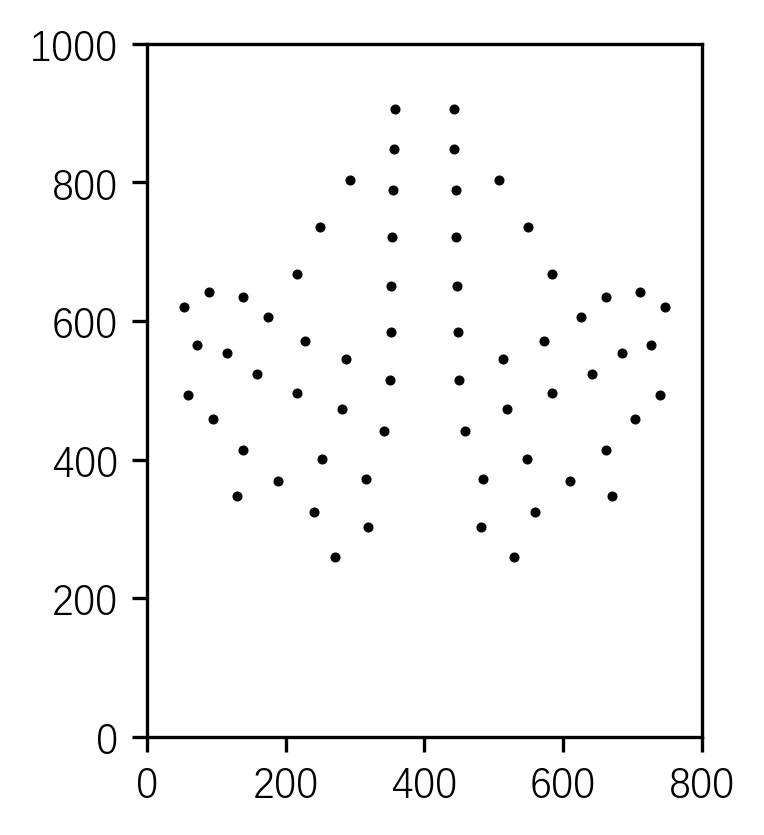

In [4]:
pdf = fitz.open("viz/electrodes.pdf")
page = pdf[0]
H = page.rect.height
W = page.rect.width
fig, ax = plt.subplots()

centers = []

for d in page.get_drawings():

    r = d["rect"]

    centers.append([
        (r.x0+r.x1)/2,
        (H-r.y0+H-r.y1)/2
    ])
centers = np.array(centers)
plt.scatter(*np.array(centers).T, s=2, marker="o", color="k")
np.array(centers).shape
ax.set_xlim(0, W)
ax.set_ylim(0, H)
ax.set_aspect("equal")
# ax.axis("off")

In [5]:
import pandas as pd
from scipy.spatial.distance import cdist
from sklearn.preprocessing import MinMaxScaler
import mne
from bmi_free.io import path

df_loc = pd.read_excel(path['config'] / "elec_loc_64_20250606_with_palette_gray.xlsx", index_col="label")
# ================= 1. 数据准备与假设 =================
# 假设 df 包含 'r', 'a', 's' 三列真实三维坐标
# df.index 是 channel names (如 ['Fp1', 'Fp2', ...])
loc_3d = df_loc[['r', 'a', 's']].values.astype(np.float64)
channel_names = df_loc.index.tolist()


# ================= 2. 三维坐标的二维投影与旋转 =================
pitch = -15
theta = np.radians(pitch)  # 上翘
cos_t, sin_t = np.cos(theta), np.sin(theta)

# 绕 r 轴(x轴)旋转：r不变，新的y由 a 和 s 组合而成
# "a轴上翘"意味着原来的 s 分量有一部分投影到了 y 轴上
proj_r = loc_3d[:, 0]                     # X方向：r 轴
proj_y = loc_3d[:, 1] * cos_t - loc_3d[:, 2] * sin_t  # Y方向：a-s 平面的旋转投影

# 组合成投影后的二维坐标 (64, 2)
df_proj_2d = np.column_stack((proj_r, proj_y))

# ================= 3. 双轴归一化到 [0, 1] =================
def normalize_01(arr):
    min_vals = arr.min(axis=0)
    max_vals = arr.max(axis=0)
    ranges = max_vals - min_vals
    ranges[ranges == 0] = 1.0 
    return (arr - min_vals) / ranges

df_norm = MinMaxScaler().fit_transform(df_proj_2d)
centers_norm = MinMaxScaler().fit_transform(centers)

# ================= 4. 距离比对与顺序对齐 =================
dist_matrix = cdist(df_norm, centers_norm, metric='euclidean')

# 找到每个 df 对应的最近的 center 索引 (沿着 axis=1 找最小值)
matched_center_indices = np.argmin(dist_matrix, axis=1) 

# 【关键】按照 df 的原始顺序，提取对应的 centers 像素坐标
# 这样 reordered_centers 的第 i 行，就对应 df 的第 i 行 (即 channel_names[i])
reordered_centers = centers[matched_center_indices]

# 验证残差
residuals = np.min(dist_matrix, axis=1)
print(f"最大归一化匹配误差: {np.max(residuals):.4f}")

# ================= 5. 绘制归一化后的对比图 =================
plt.figure(figsize=(4, 4))

plt.scatter(centers_norm[:, 0], centers_norm[:, 1], 
            s=10, label='Extracted Centers', zorder=5, alpha=.5)
plt.scatter(df_norm[:, 0], df_norm[:, 1], 
            s=10, label='3D Projected Points', zorder=4, alpha=.5)

# for i, name in enumerate(channel_names):
#     plt.text(df_norm[i, 0], df_norm[i, 1], name, fontsize=7, ha='right', va='bottom')

# 画匹配连线
for i in range(len(df_norm)):
    center_idx = matched_center_indices[i]
    plt.plot([df_norm[i, 0], centers_norm[center_idx, 0]], 
             [df_norm[i, 1], centers_norm[center_idx, 1]], 
             'gray', linestyle='--', alpha=0.5)

plt.xlabel('Normalized R-axis')
plt.ylabel('Normalized Rotated AS-axis')
# plt.legend()
plt.axis('equal')  
plt.show()

# ================= 6. 构建与 df 严格同序的 DigMontage =================
ch_pos_dict = {}
for i, ch_name in enumerate(channel_names):
    # 直接按顺序取 reordered_centers 中的坐标
    x, y = reordered_centers[i]
    ch_pos_dict[ch_name] = np.array([x, y, 0.0]) 

# 创建 DigMontage
montage = mne.channels.make_dig_montage(ch_pos=ch_pos_dict, coord_frame='head')

# # 验证 Montage 的通道顺序是否与 df 一致
# print("Montage 通道顺序:", montage.ch_names)
# print("DF 通道顺序:    ", channel_names)
# print("顺序是否一致:", montage.ch_names == channel_names)

FileNotFoundError: [Errno 2] No such file or directory: 'F:\\bmi_free_01\\data\\config\\elec_loc_64_20250606_with_palette_gray.xlsx'

In [ ]:
pd.DataFrame(montage.get_positions()['ch_pos']).T

,0,1,2
L11,357.576706,906.050030,0.0
L12,356.573608,848.282478,0.0
L13,292.880508,803.074623,0.0
L14,354.286591,789.170471,0.0
L15,250.107811,735.591805,0.0
...,...,...,...
R44,670.109283,348.161530,0.0
R45,610.618073,369.641205,0.0
R46,558.976990,323.849030,0.0
R47,529.399368,259.077118,0.0


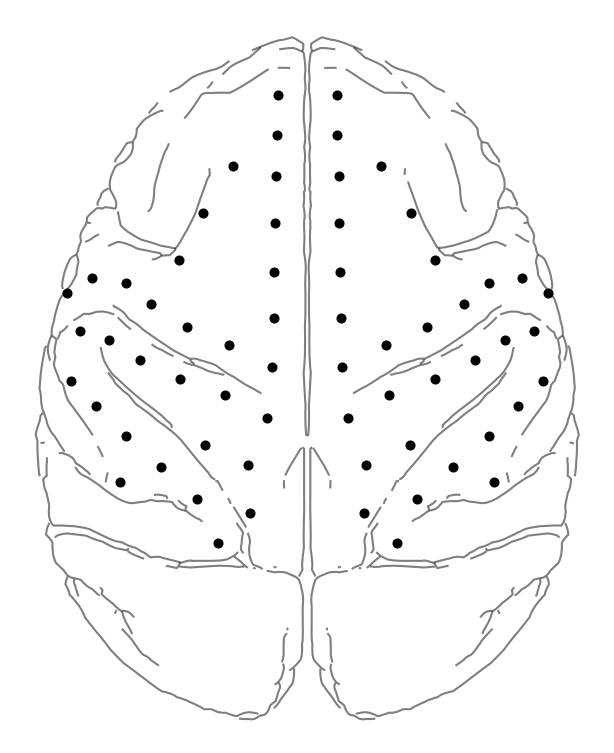

In [ ]:
plot_cortical_frame()
elec_loc = pd.DataFrame(montage.get_positions()['ch_pos']).T
plt.scatter(elec_loc[0], elec_loc[1], s=2, marker="o", color="k")
plt.show()

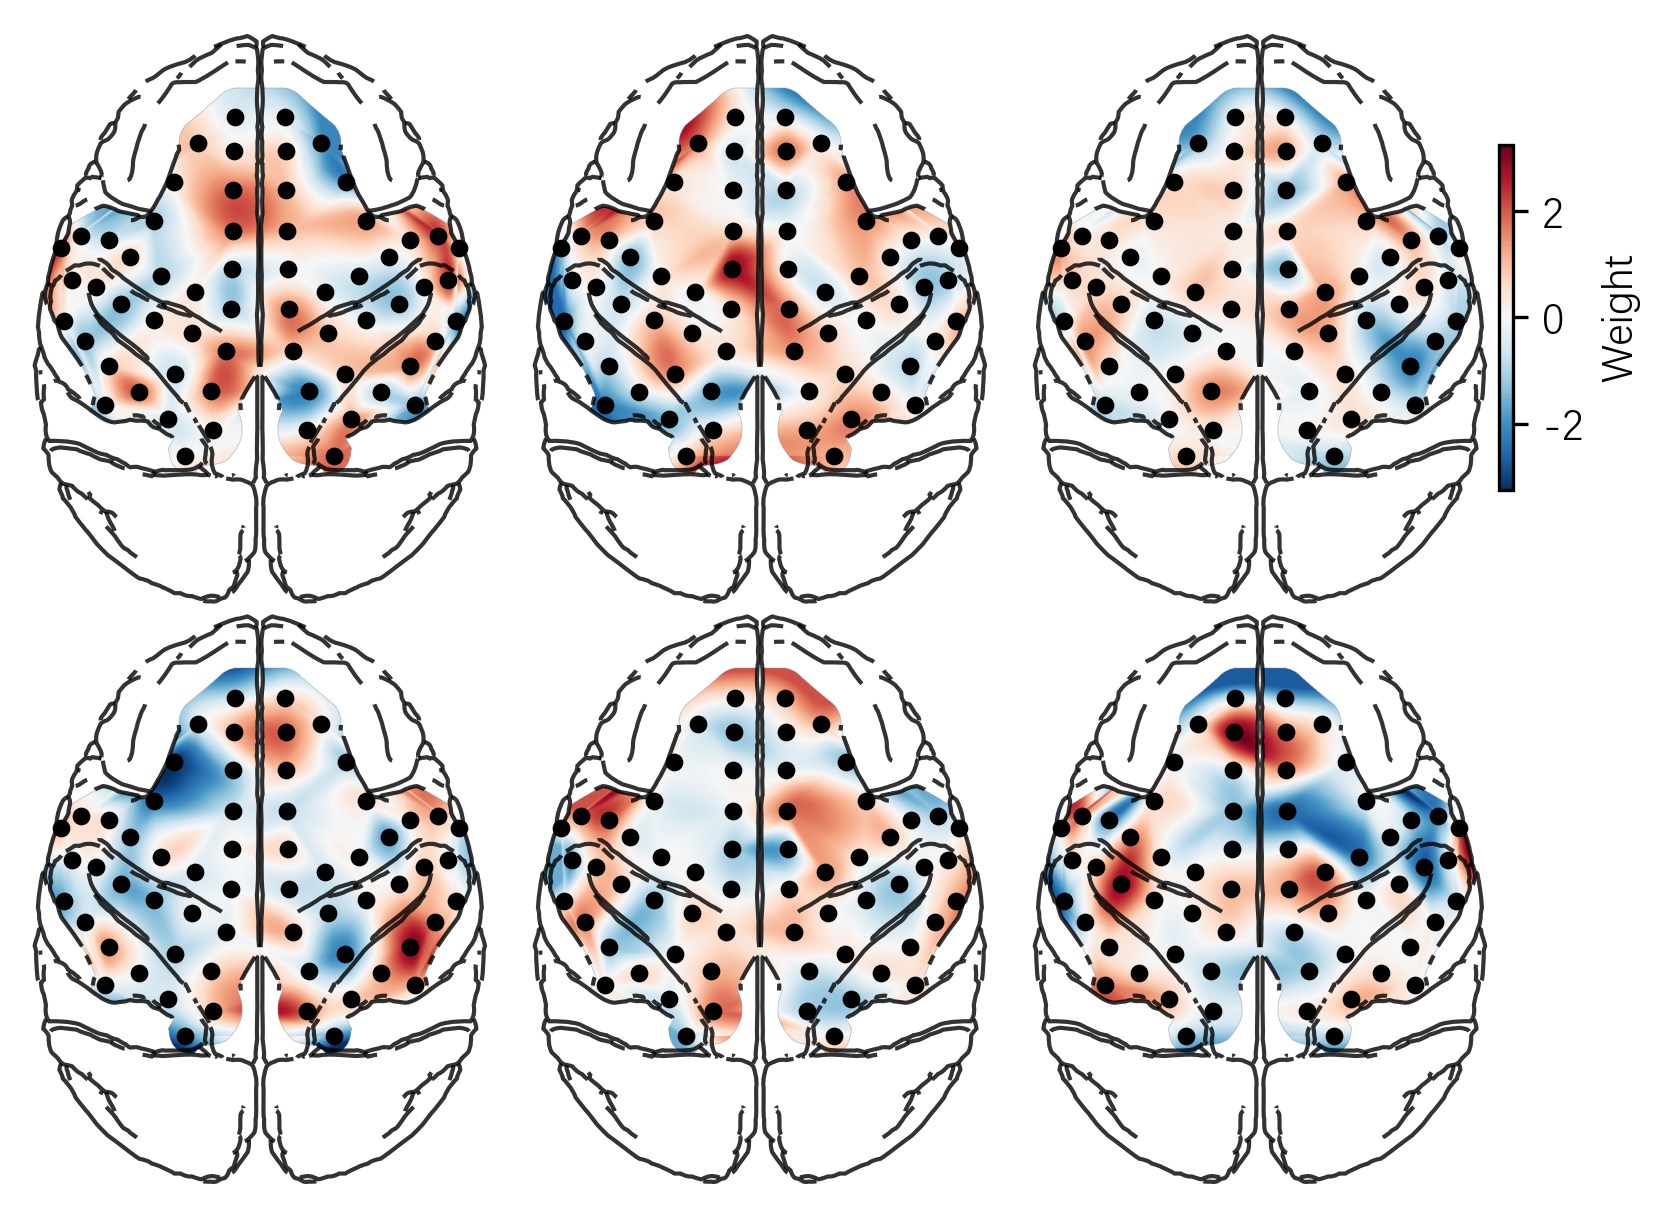

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from bmi_free.viz import plot_topomap_grid

# 你的 62 维数据
data = np.random.randn(2, 3, 62)

fig, ax = plot_topomap_grid(
    data,
    cmap="RdBu_r",
    cbar_label="Weight",
    share_lim='all'
)
plt.show()